In [2]:
import torch
import torch.nn as nn
torch.manual_seed(42)
import torch.optim as optim
from torchinfo import summary
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models, datasets

import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [4]:
import os
count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        break
    if count ==10:
        break
    count+=1

/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Tomato___Late_blight/1e5ba644-efeb-4bd3-b878-a0606cf8a992___RS_Late.B 6272_flipLR.JPG
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Tomato___healthy/df35d1fb-978c-4aeb-9d6f-e7da242c81b8___RS_HL 0515.JPG
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Grape___healthy/d68b653c-4fe7-49ee-80d4-1f0c84092242___Mt.N.V_HL 6077_90deg.JPG
/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid/Orange___Haunglongbing_(Citrus_greening)/a35e0371-6ee2-4d96-a4cc-9677d51b01d2___CREC_HLB 4423.JPG


In [5]:
path =  "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"
path

'/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset'

In [6]:
train_path = path + r"/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
val_path =  path + r"/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"
test_path =  path + r"/test/test"

In [7]:
print(os.listdir(train_path))

['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Potato___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Early_blight', 'Tomato___Septoria_leaf_spot', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Strawberry___Leaf_scorch', 'Peach___healthy', 'Apple___Apple_scab', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Bacterial_spot', 'Apple___Black_rot', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Peach___Bacterial_spot', 'Apple___Cedar_apple_rust', 'Tomato___Target_Spot', 'Pepper,_bell___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Potato___Late_blight', 'Tomato___Tomato_mosaic_virus', 'Strawberry___healthy', 'Apple___healthy', 'Grape___Black_rot', 'Potato___Early_blight', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Common_rust_', 'Grape___Esca_(Black_Measles)', 'Raspberry___healthy', 'Tomato___Leaf_Mold', 'Tomato__

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,.456,.406],
        [.229,.224,.225]
    )
])
val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485,.456,.406],
        [.229,.224,.225]
    )
])

In [9]:
train_dataset = datasets.ImageFolder(
    train_path,
    transform = train_transform
)

val_dataset = datasets.ImageFolder(
    val_path,
    transform = val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size = 128,
    shuffle = True,
    num_workers=4,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size = 128,
    shuffle = False,
    num_workers=4,
    pin_memory=True
)

In [10]:
from PIL import Image
class testdataset(Dataset):
    def __init__(self, test_path, transform = None):
        self.path = test_path
        self.transform  = transform
        self.images = [f for f in os.listdir(self.path)
                      if f.lower().endswith((".jpg",".jpeg",".png"))]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_name = self.images[idx]
        image_path = os.path.join(self.path, image_name)
        image = Image.open(image_path)
        if self.transform:
            image = self.transform(image)

        return image, image_name

test_dataset = testdataset(test_path, val_transform)

test_loader =  DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [11]:
images,  labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

torch.Size([128, 3, 224, 224])
torch.Size([128])


In [12]:
from collections import Counter

counts = Counter(train_dataset.targets)
i =0
for idx, count in counts.items():
    i +=1
    print(f"{i:2d}. {train_dataset.classes[idx]:50s}: {count} images")

 1. Apple___Apple_scab                                : 2016 images
 2. Apple___Black_rot                                 : 1987 images
 3. Apple___Cedar_apple_rust                          : 1760 images
 4. Apple___healthy                                   : 2008 images
 5. Blueberry___healthy                               : 1816 images
 6. Cherry_(including_sour)___Powdery_mildew          : 1683 images
 7. Cherry_(including_sour)___healthy                 : 1826 images
 8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1642 images
 9. Corn_(maize)___Common_rust_                       : 1907 images
10. Corn_(maize)___Northern_Leaf_Blight               : 1908 images
11. Corn_(maize)___healthy                            : 1859 images
12. Grape___Black_rot                                 : 1888 images
13. Grape___Esca_(Black_Measles)                      : 1920 images
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)        : 1722 images
15. Grape___healthy                             

# densenet architecture

In [13]:
class denselayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super().__init__()
        self.layer = nn.Sequential(
            nn.BatchNorm2d(in_channels),
            nn.ReLU(),
            nn.Conv2d(in_channels, growth_rate, kernel_size=3, padding=1, bias=False)
        )
    def forward(self, x):
        new_features = self.layer(x)
        return torch.cat([x, new_features], dim = 1)

class denseblock(nn.Module):
    def __init__(self, in_channels, num_layers, growth_rate):
        super().__init__()

        self.layers = nn.ModuleList()

        for i in range(num_layers):
            layer = denselayer(in_channels + i *growth_rate, growth_rate)
            self.layers.append(layer)

    def forward(self,x):
        for layer in self.layers:
            x = layer(x)
        return x

class transitionlayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layer = nn.Sequential(
            nn.BatchNorm2d(in_channels),
            nn.ReLU(),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
    def forward(self, x):
        return self.layer(x)

class densenet(nn.Module):
    def __init__(self, num_classes = 38, growth_rate = 32, block_layers = (1,1,1)):
        super().__init__()

        channels = growth_rate

        self.stem = nn.Sequential(
            nn.Conv2d( 3, channels, kernel_size=3, stride=1, padding=1, bias=False ),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

        self.block1 = denseblock(channels, block_layers[0], growth_rate )

        channels += block_layers[0] * growth_rate
        out_channels = channels // 2

        self.trans1 = transitionlayer(channels, out_channels)

        channels = out_channels

        self.block2 = denseblock(channels, block_layers[1], growth_rate )

        channels += block_layers[1] * growth_rate
        out_channels = channels // 2

        self.trans2 = transitionlayer(channels, out_channels)

        channels = out_channels

        self.block3 = denseblock(channels, block_layers[2], growth_rate )

        channels += block_layers[2] * growth_rate

        self.final_layers = nn.Sequential(
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(channels, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.trans1(x)
        x = self.block2(x)
        x = self.trans2(x)
        x = self.block3(x)
        return self.final_layers(x)


In [14]:
model = densenet(num_classes=38).to(device)

images = torch.randn(2, 3, 224, 224).to(device)
outputs = model(images)

print(outputs.shape)

torch.Size([2, 38])


In [15]:
model = densenet( num_classes = 38, growth_rate = 32, block_layers = (3,3,3))
print(f"Using {torch.cuda.device_count()} GPUs!")
model = nn.DataParallel(model)

model = model.to(device)

Using 2 GPUs!


In [16]:
summary(model)

Layer (type:depth-idx)                             Param #
DataParallel                                       --
├─densenet: 1-1                                    --
│    └─Sequential: 2-1                             --
│    │    └─Conv2d: 3-1                            864
│    │    └─BatchNorm2d: 3-2                       64
│    │    └─ReLU: 3-3                              --
│    └─denseblock: 2-2                             --
│    │    └─ModuleList: 3-4                        55,680
│    └─transitionlayer: 2-3                        --
│    │    └─Sequential: 3-5                        8,448
│    └─denseblock: 2-4                             --
│    │    └─ModuleList: 3-6                        83,520
│    └─transitionlayer: 2-5                        --
│    │    └─Sequential: 3-7                        13,120
│    └─denseblock: 2-6                             --
│    │    └─ModuleList: 3-8                        97,440
│    └─Sequential: 2-7                             --
│  

In [17]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001,
    weight_decay=1e-4
)
#--------------------------------------------
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [18]:
epochs = 30

best_val_loss = float("inf")
patience = 5
counter = 0

train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []


for i in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    scaler = torch.amp.GradScaler('cuda')

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'): # for utilizing kaggle t4 x2 gpu
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()* images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total

    #-------------------------------------
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_running_loss += loss.item()* images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss) # learning-rate scheduler

    # Store metrics
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    print(
        f"Epoch [{i+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # ----------------- early stoping -------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0

        torch.save(model.state_dict(), "best_plant_model.pth")

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered!")
        break

model.load_state_dict(
    torch.load("best_plant_model.pth", map_location=device, weights_only=True)
)

Epoch [1/30] | Train Loss: 1.4930 | Val Loss: 0.7328 | Train Acc: 61.07% | Val Acc: 78.92%
Epoch [2/30] | Train Loss: 0.7200 | Val Loss: 0.6102 | Train Acc: 79.20% | Val Acc: 81.73%
Epoch [3/30] | Train Loss: 0.5233 | Val Loss: 0.3845 | Train Acc: 84.42% | Val Acc: 88.40%
Epoch [4/30] | Train Loss: 0.4252 | Val Loss: 0.2715 | Train Acc: 87.24% | Val Acc: 91.90%
Epoch [5/30] | Train Loss: 0.3596 | Val Loss: 0.3354 | Train Acc: 89.09% | Val Acc: 89.44%
Epoch [6/30] | Train Loss: 0.3148 | Val Loss: 0.2666 | Train Acc: 90.38% | Val Acc: 91.78%
Epoch [7/30] | Train Loss: 0.2778 | Val Loss: 0.1902 | Train Acc: 91.49% | Val Acc: 94.16%
Epoch [8/30] | Train Loss: 0.2442 | Val Loss: 0.1511 | Train Acc: 92.71% | Val Acc: 95.60%
Epoch [9/30] | Train Loss: 0.2257 | Val Loss: 0.1543 | Train Acc: 93.00% | Val Acc: 95.48%
Epoch [10/30] | Train Loss: 0.2016 | Val Loss: 0.1411 | Train Acc: 93.84% | Val Acc: 95.69%
Epoch [11/30] | Train Loss: 0.1910 | Val Loss: 0.1408 | Train Acc: 94.16% | Val Acc: 95.7

<All keys matched successfully>

In [35]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 98.96%


In [19]:
from sklearn.metrics import classification_report
model.eval()

y_true=[]
y_pred=[]
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        pred = torch.argmax(outputs, dim = 1)
        y_true.extend(labels.numpy())
        y_pred.extend(pred.cpu().numpy())

print(classification_report(
    y_true,
    y_pred,
    target_names = train_dataset.classes
))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       0.99      1.00      0.99       440
                                   Apple___healthy       1.00      0.99      0.99       502
                               Blueberry___healthy       0.99      1.00      0.99       454
          Cherry_(including_sour)___Powdery_mildew       0.99      1.00      1.00       421
                 Cherry_(including_sour)___healthy       0.99      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.86      0.91       410
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       477
               Corn_(maize)___Northern_Leaf_Blight       0.90      0.99      0.

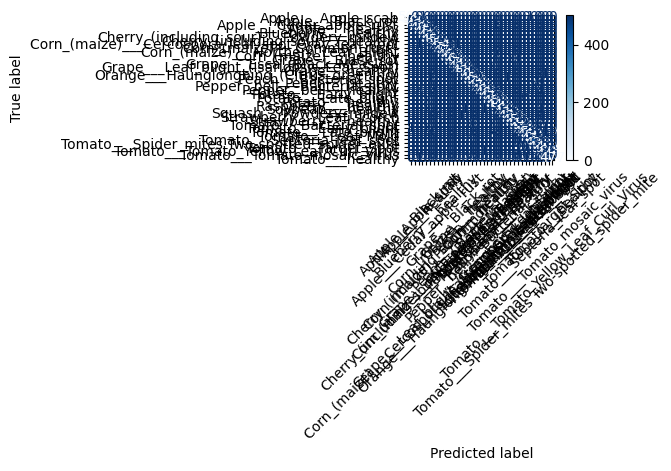

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

model.eval()
all_preds = []
all_labels = []

class_names = train_dataset.classes

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")

plt.tight_layout()
plt.show()

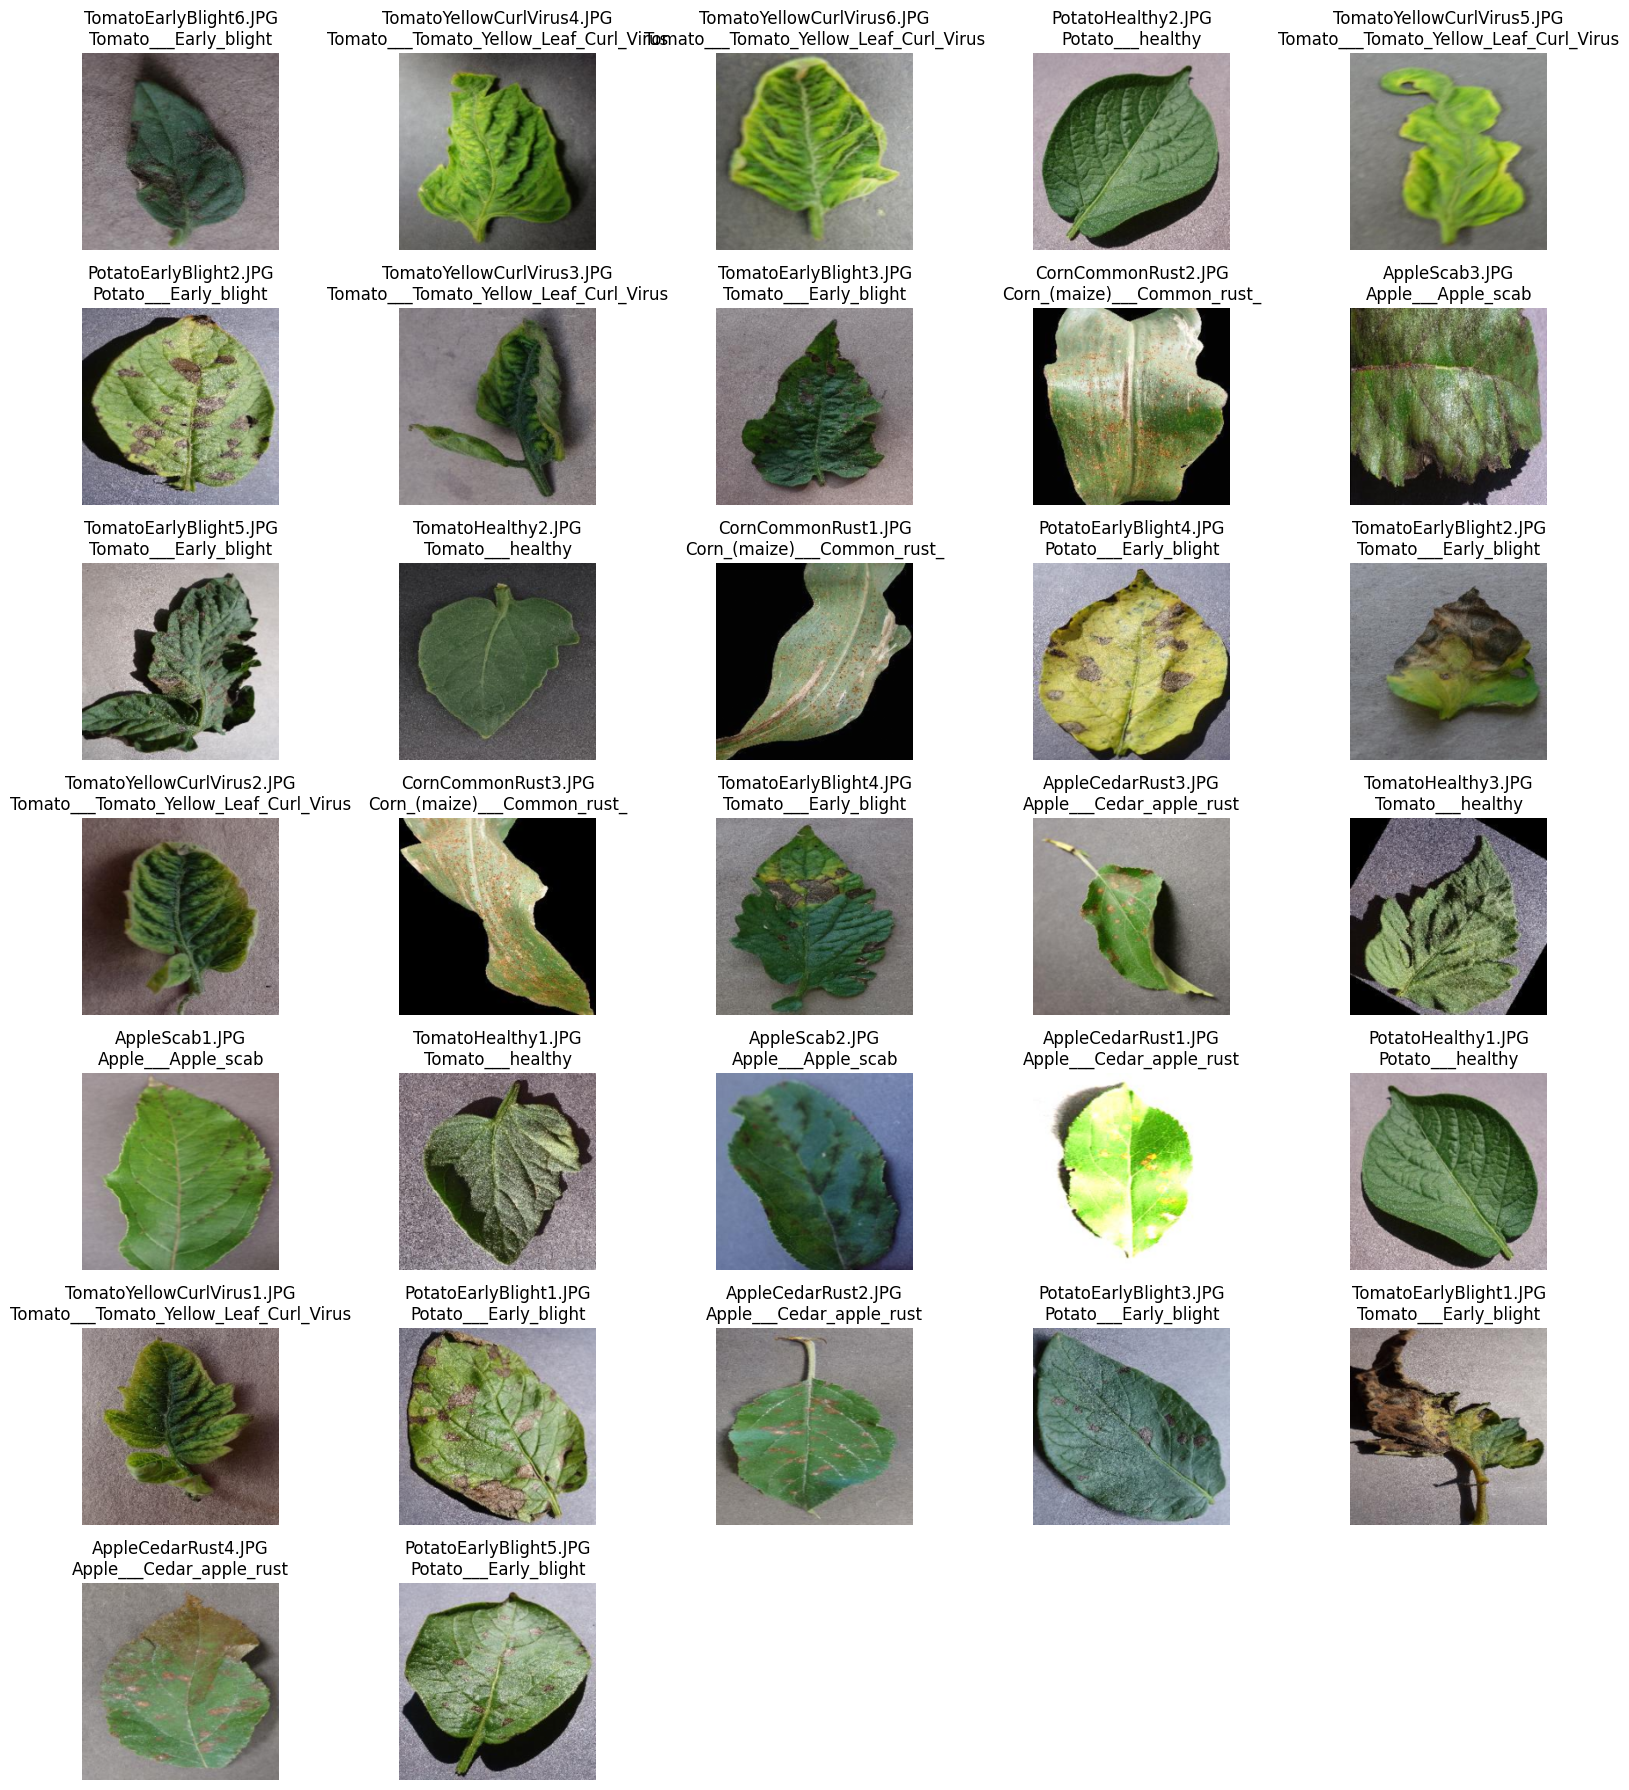

In [30]:
import matplotlib.pyplot as plt
import torch

model.eval()

images, filenames = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1).cpu()

# Reverse ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

classes = train_dataset.classes

n = len(images)
fig, axes = plt.subplots(7, 5, figsize=(16, 18))

for i, ax in enumerate(axes.flatten()):
    if i >= n:
        ax.axis("off")
        continue

    img = images[i].cpu() * std + mean
    img = img.clamp(0, 1).permute(1, 2, 0)

    pred_label = classes[predictions[i].item()]

    ax.imshow(img)
    ax.set_title(f"{filenames[i]}\n{pred_label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [40]:
import yaml

config = {
    "model": {
        "name": "densenet",
        "format": "torchscript",
        "file": "plant_model.pt",
        "input": {
            "channels": 3,
            "height": 224,
            "width": 224,
            "color_mode": "RGB"
        },
        "preprocessing": {
            "resize": [224, 224],
            "convert_to_tensor": True,
            "normalize": {
            "mean": [0.485, 0.456, 0.406],  
            "std": [0.229, 0.224, 0.225],  
        }
        }
    },
    "classes": train_dataset.classes,
    
}

with open("plant_model.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

In [34]:
base_model = model.module if isinstance(
    model, torch.nn.DataParallel
) else model

model.eval()

example_input = torch.randn(1, 3, 224, 224).to(device)

scripted_model = torch.jit.trace(base_model, example_input, check_trace=False)

scripted_model.save("plant_model.pt")

In [37]:
!rm -f /kaggle/working/best_plant_model.pth